In [ ]:
'''
Evaluate support vector machine (SVM) classifiers with different kernels (linear, RBF, polynomial),
tuning hyperparameters to maximize classification performance on applicant datasets.
'''

In [40]:
# import the required libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [41]:
df = pd.read_csv("Adm.csv")
display(df.head())
print("\ncolumn information:")
df.info()

# check missing values
print("\nmissing values:")
print(df.isnull().sum())

,Serial No.,GRE Score,TOEFL Score,University Rating,SOP,LOR,CGPA,Research,Chance of Admit,Application_DateTime,University_Name,region
0,1,337,118,4,4.5,4.5,9.65,1,0.92,2022-01-01 09:00:00,Indian Institute of Technology Kharagpur,East
1,2,324,107,4,4.0,4.5,8.87,1,0.76,2022-01-02 09:00:00,National Institute of Technology Karnataka,South
2,3,316,104,3,3.0,3.5,8.00,1,0.72,2022-01-04 09:00:00,Gujarat University,West
3,4,322,110,3,3.5,2.5,8.67,1,0.80,2022-01-06 09:00:00,Jamia Millia Islamia,North
4,5,314,103,2,2.0,3.0,8.21,0,0.65,2022-01-08 09:00:00,Jamia Millia Islamia,North



column information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 12 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   Serial No.            1000 non-null   int64  
 1   GRE Score             1000 non-null   int64  
 2   TOEFL Score           1000 non-null   int64  
 3   University Rating     1000 non-null   int64  
 4   SOP                   1000 non-null   float64
 5   LOR                   1000 non-null   float64
 6   CGPA                  1000 non-null   float64
 7   Research              1000 non-null   int64  
 8   Chance of Admit       1000 non-null   float64
 9   Application_DateTime  1000 non-null   object 
 10  University_Name       1000 non-null   object 
 11  region                1000 non-null   object 
dtypes: float64(4), int64(5), object(3)
memory usage: 93.9+ KB

missing values:
Serial No.              0
GRE Score               0
TOEFL Score             0
U

In [42]:
#dataprepare the data for classification
# remove rows with missing values in the required target
df = df.dropna(subset=["Chance of Admit"]).copy()

# convert admission chances into two classes
# 1 means likely admit and 0 means less likely admit
df["Admission_Status"] = (
    df["Chance of Admit"] >= 0.70
).astype(int)

# display the number of applicants in each class
print("admission class distribution:")
print(df["Admission_Status"].value_counts())

# display the class distribution in percentages
print("\nclass percentages:")
print(
    (df["Admission_Status"].value_counts(normalize=True) * 100)
    .round(2)
)

admission class distribution:
Admission_Status
1    594
0    406
Name: count, dtype: int64

class percentages:
Admission_Status
1    59.4
0    40.6
Name: proportion, dtype: float64


In [43]:
# select feature targets 
# select academic and application-related features
features = [
    "GRE Score",
    "TOEFL Score",
    "University Rating",
    "SOP",
    "LOR",
    "CGPA",
    "Research",
    "University_Name",
    "region"
]

# separate input features and target
X = df[features]
y = df["Admission_Status"]

# identify numerical and categorical columns
numeric_features = [
    "GRE Score",
    "TOEFL Score",
    "University Rating",
    "SOP",
    "LOR",
    "CGPA",
    "Research"
]

categorical_features = [
    "University_Name",
    "region"
]

print("input shape:", X.shape)
print("target shape:", y.shape)
print("\nselected features:")
print(features)

input shape: (1000, 9)
target shape: (1000,)

selected features:
['GRE Score', 'TOEFL Score', 'University Rating', 'SOP', 'LOR', 'CGPA', 'Research', 'University_Name', 'region']


In [44]:
from sklearn.model_selection import train_test_split 
# train and test data 
# split the data into training and testing sets
# stratify keeps the class proportions similar in both sets
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("training records:", X_train.shape[0])
print("testing records:", X_test.shape[0])

training records: 800
testing records: 200


In [45]:
# process features scale numeric values and encode categories
# scale numerical features and convert categorical features into numbers

from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
preprocessor = ColumnTransformer(
    transformers=[
        (
            "numeric",
            StandardScaler(),
            numeric_features
        ),
        (
            "categorical",
            OneHotEncoder(handle_unknown="ignore"),
            categorical_features
        )
    ]
)


In [46]:
#define the svm model and parameter grids with diffrent kersnel
# create an svm pipeline with preprocessing
from sklearn.pipeline import Pipeline
from sklearn.svm import SVC
svm_pipeline = Pipeline([
    ("preprocessing", preprocessor),
    ("svm", SVC())
])

# define different hyperparameter combinations for each kernel
param_grids = {
    "Linear": {
        "svm__kernel": ["linear"],
        "svm__C": [0.1, 1, 10, 100],
        "svm__class_weight": [None, "balanced"]
    },

    "RBF": {
        "svm__kernel": ["rbf"],
        "svm__C": [0.1, 1, 10, 100],
        "svm__gamma": ["scale", 0.01, 0.1, 1],
        "svm__class_weight": [None, "balanced"]
    },

    "Polynomial": {
        "svm__kernel": ["poly"],
        "svm__C": [0.1, 1, 10],
        "svm__degree": [2, 3],
        "svm__gamma": ["scale", 0.1],
        "svm__coef0": [0, 1],
        "svm__class_weight": [None, "balanced"]
    }
}


In [47]:
#train and tune all three kernels using gridsearch_cv
# store the best model and its evaluation results
from sklearn.model_selection import GridSearchCV 
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

best_models = {}
results = []

# test each kernel using cross-validation
for kernel_name, parameters in param_grids.items():

    print(f"\ntuning {kernel_name} kernel...")

    # search for the best parameter combination
    grid_search = GridSearchCV(
        estimator=svm_pipeline,
        param_grid=parameters,
        scoring="f1",
        cv=5,
        n_jobs=-1,
        refit=True
    )

    # train and tune the model using training data only
    grid_search.fit(X_train, y_train)

    # save the best model for this kernel
    best_models[kernel_name] = grid_search.best_estimator_

    # predict the unseen test data
    y_pred = grid_search.predict(X_test)

    # calculate the evaluation metrics
    results.append({
        "Kernel": kernel_name,
        "Best CV F1": grid_search.best_score_,
        "Test Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(
            y_test, y_pred, zero_division=0
        ),
        "Recall": recall_score(
            y_test, y_pred, zero_division=0
        ),
        "F1 Score": f1_score(
            y_test, y_pred, zero_division=0
        ),
        "Best Parameters": grid_search.best_params_
    })

    print("best parameters:", grid_search.best_params_)
    print("best cross-validation f1:", round(grid_search.best_score_, 4))

# convert the results into a dataframe
results_df = pd.DataFrame(results)

print("\nmodel comparison:")
display(
    results_df.drop(columns=["Best Parameters"])
    .round(4)
    .sort_values("F1 Score", ascending=False)
    .reset_index(drop=True)
)


tuning Linear kernel...
best parameters: {'svm__C': 0.1, 'svm__class_weight': None, 'svm__kernel': 'linear'}
best cross-validation f1: 0.7115

tuning RBF kernel...
best parameters: {'svm__C': 0.1, 'svm__class_weight': None, 'svm__gamma': 'scale', 'svm__kernel': 'rbf'}
best cross-validation f1: 0.7702

tuning Polynomial kernel...
best parameters: {'svm__C': 0.1, 'svm__class_weight': None, 'svm__coef0': 0, 'svm__degree': 3, 'svm__gamma': 0.1, 'svm__kernel': 'poly'}
best cross-validation f1: 0.7648

model comparison:


,Kernel,Best CV F1,Test Accuracy,Precision,Recall,F1 Score
0,RBF,0.7702,0.655,0.6437,0.9412,0.7645
1,Polynomial,0.7648,0.630,0.6166,1.0000,0.7628
2,Linear,0.7115,0.665,0.6806,0.8235,0.7452


In [48]:
# display the best parameter combination for each kernel
for kernel_name, model in best_models.items():

    print(f"\n{kernel_name} kernel")

    # display the selected svm parameters
    print(
        model.named_steps["svm"].get_params()
    )


Linear kernel
{'C': 0.1, 'break_ties': False, 'cache_size': 200, 'class_weight': None, 'coef0': 0.0, 'decision_function_shape': 'ovr', 'degree': 3, 'gamma': 'scale', 'kernel': 'linear', 'max_iter': -1, 'probability': False, 'random_state': None, 'shrinking': True, 'tol': 0.001, 'verbose': False}

RBF kernel
{'C': 0.1, 'break_ties': False, 'cache_size': 200, 'class_weight': None, 'coef0': 0.0, 'decision_function_shape': 'ovr', 'degree': 3, 'gamma': 'scale', 'kernel': 'rbf', 'max_iter': -1, 'probability': False, 'random_state': None, 'shrinking': True, 'tol': 0.001, 'verbose': False}

Polynomial kernel
{'C': 0.1, 'break_ties': False, 'cache_size': 200, 'class_weight': None, 'coef0': 0, 'decision_function_shape': 'ovr', 'degree': 3, 'gamma': 0.1, 'kernel': 'poly', 'max_iter': -1, 'probability': False, 'random_state': None, 'shrinking': True, 'tol': 0.001, 'verbose': False}


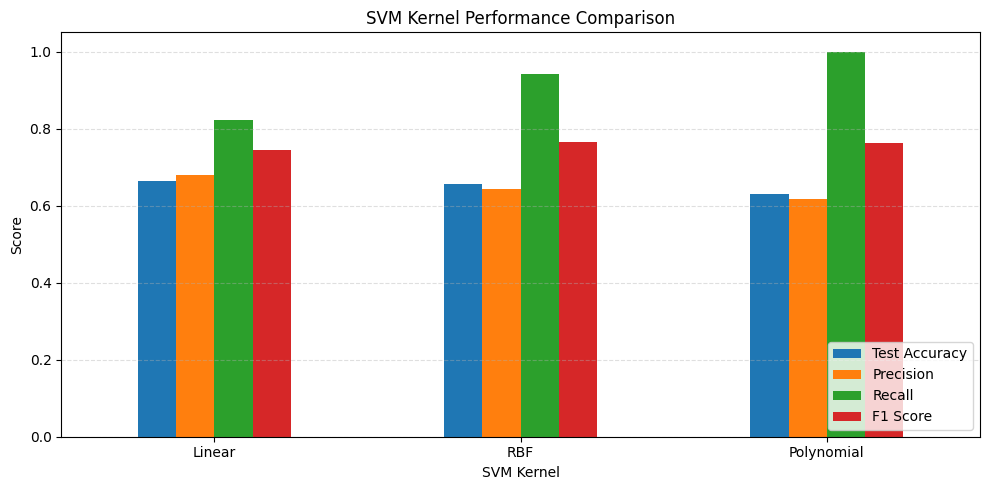

In [49]:
# compare the test performance of all three kernels
metrics = [
    "Test Accuracy",
    "Precision",
    "Recall",
    "F1 Score"
]

results_plot = results_df.set_index("Kernel")[metrics]

# create a grouped bar chart
results_plot.plot(
    kind="bar",
    figsize=(10, 5),
    ylim=(0, 1.05),
    rot=0
)

plt.title("SVM Kernel Performance Comparison")
plt.xlabel("SVM Kernel")
plt.ylabel("Score")
plt.legend(loc="lower right")
plt.grid(axis="y", linestyle="--", alpha=0.4)
plt.tight_layout()
plt.show()

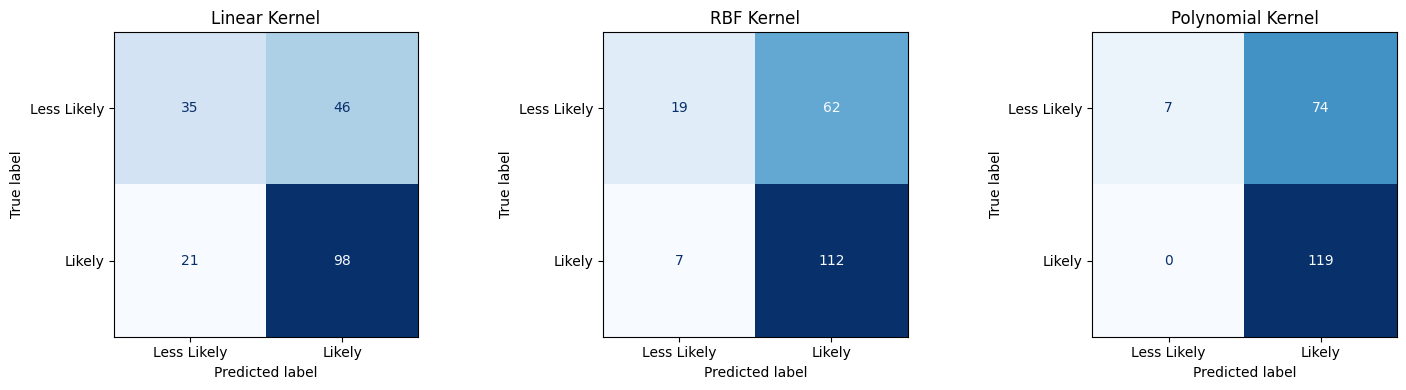

In [50]:
# confusion matrix for each tuned model

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for ax, (kernel_name, model) in zip(
    axes, best_models.items()
):

    # predict admission classes on the test data
    y_pred = model.predict(X_test)

    # compare actual and predicted classes
    cm = confusion_matrix(
        y_test,
        y_pred,
        labels=[0, 1]
    )

    # display the confusion matrix
    display_matrix = ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=["Less Likely", "Likely"]
    )

    display_matrix.plot(
        ax=ax,
        cmap="Blues",
        colorbar=False
    )

    ax.set_title(f"{kernel_name} Kernel")

plt.tight_layout()
plt.show()

In [51]:
# select the model with the highest test f1-score
best_row = results_df.loc[
    results_df["F1 Score"].idxmax()
]

best_kernel = best_row["Kernel"]
best_model = best_models[best_kernel]

# make predictions with the selected model
y_pred_best = best_model.predict(X_test)

print("best kernel:", best_kernel)
print("test accuracy:", round(
    accuracy_score(y_test, y_pred_best), 4
))
print("\nclassification report:")
print(
    classification_report(
        y_test,
        y_pred_best,
        labels=[0, 1],
        target_names=["Less Likely Admit", "Likely Admit"],
        zero_division=0
    )
)

print("best hyperparameters:")
print(best_row["Best Parameters"])

best kernel: RBF
test accuracy: 0.655

classification report:
                   precision    recall  f1-score   support

Less Likely Admit       0.73      0.23      0.36        81
     Likely Admit       0.64      0.94      0.76       119

         accuracy                           0.66       200
        macro avg       0.69      0.59      0.56       200
     weighted avg       0.68      0.66      0.60       200

best hyperparameters:
{'svm__C': 0.1, 'svm__class_weight': None, 'svm__gamma': 'scale', 'svm__kernel': 'rbf'}
